In [1]:
import os
import random
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset, Subset
from PIL import Image

# ---------------- 全局 Trigger 设置 ----------------
trigger_path = r"C:\Users\Lenovo\Desktop\Blendtrigger.png"
alpha = 0.3
IMAGE_SIZE = 32  # CIFAR-10 图像尺寸

def load_full_trigger_rgb(trigger_path=None, image_size=IMAGE_SIZE):
    patch = None
    if trigger_path:
        try:
            if os.path.exists(trigger_path):
                img = Image.open(trigger_path).convert("RGB")
                img = img.resize((image_size, image_size), Image.BILINEAR)
                patch = transforms.ToTensor()(img)
                patch = patch.clamp(0.0, 1.0).float()
                print(f"[INFO] Full trigger loaded from: {trigger_path} (resized to {image_size}x{image_size}, RGB).")
            else:
                print(f"[WARN] trigger_path 指定的文件不存在: {trigger_path} ，使用默认全 1 trigger。")
        except Exception as e:
            print(f"[WARN] 无法读取 trigger 图片（{trigger_path}），使用默认全 1 trigger。错误：{e}")

    if patch is None:
        patch = torch.ones((3, image_size, image_size), dtype=torch.float32)
        print("[INFO] 使用默认全 1（白色）full-coverage trigger（RGB）。")

    if patch.ndim == 2:
        patch = patch.unsqueeze(0)
    assert patch.shape == (3, image_size, image_size), f"trigger shape must be (3,{image_size},{image_size}), got {patch.shape}"
    return patch

# 全局 trigger 变量
trigger = load_full_trigger_rgb(trigger_path, image_size=IMAGE_SIZE)
# ----------------------------------------------------------------
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(64 * 16 * 16, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))      # [B, 32, 32, 32]
        x = F.relu(self.conv2(x))      # [B, 64, 32, 32]
        x = self.pool(x)               # [B, 64, 16, 16]
        x = x.view(-1, 64 * 16 * 16)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

# ---------------- 投毒器（Blend 攻击，RGB 版） ----------------
class BlendPoisoner:
    def __init__(self, dataset, poison_rate=0.003, target_class=0, alpha=0.3, trigger=None):
        self.dataset = dataset
        self.poison_rate = poison_rate
        self.target_class = target_class
        self.alpha = alpha
        self.num_img = len(dataset)
        self.trigger = trigger if trigger is not None else globals()['trigger']
        assert self.trigger.ndim == 3 and self.trigger.shape[0] == 3, "trigger must be shape (3,H,W)"

    def generate_poison_only(self):
        idxs = list(range(self.num_img))
        random.shuffle(idxs)
        num_poison = int(self.num_img * self.poison_rate)
        poison_idxs = idxs[:num_poison]

        poison_data, poison_labels = [], []
        for i in poison_idxs:
            img, _ = self.dataset[i]
            poisoned = (1.0 - self.alpha) * img + self.alpha * self.trigger
            poisoned = torch.clamp(poisoned, 0.0, 1.0)
            poison_data.append(poisoned)
            poison_labels.append(self.target_class)

        if len(poison_data) == 0:
            return torch.empty((0, 3, IMAGE_SIZE, IMAGE_SIZE)), torch.LongTensor([]), poison_idxs
        return torch.stack(poison_data), torch.LongTensor(poison_labels), poison_idxs

    def generate_combined_dataset(self):
        orig_data = torch.stack([img for img, _ in self.dataset])
        orig_labels = torch.LongTensor([label for _, label in self.dataset])
        poison_data, poison_labels, _ = self.generate_poison_only()
        total_data = torch.cat([orig_data, poison_data], dim=0)
        total_labels = torch.cat([orig_labels, poison_labels], dim=0)
        print(f"[INFO] Combined dataset size: {total_data.shape[0]} (Clean: {len(orig_data)}, Poison: {len(poison_data)})")
        return TensorDataset(total_data, total_labels)

# ---------------- 数据加载 ----------------
def get_train_loader(poison_rate=0.003, batch_size=64, target_class=0, alpha=0.3):
    transform = transforms.ToTensor()
    train_ds = datasets.CIFAR10(root='./data', train=True, transform=transform, download=True)
    poisoner = BlendPoisoner(train_ds, poison_rate, target_class=target_class, alpha=alpha, trigger=trigger)
    combined = poisoner.generate_combined_dataset()
    loader = DataLoader(combined, batch_size=batch_size, shuffle=True)
    loader.dataset.clean_part = Subset(combined, list(range(len(train_ds))))
    loader.dataset.poison_part = Subset(combined, list(range(len(train_ds), len(combined))))
    return loader

# ---------------- 训练函数 ----------------
def train_model(model, train_loader, epochs=40, lr=1e-3, device=None, save_path="cifar10_blend_cnn4.pth"):
    if device is None:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train()
        total_loss, correct, total = 0.0, 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            outs = model(imgs)
            loss = criterion(outs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * imgs.size(0)
            _, preds = outs.max(1)
            total += labels.size(0)
            correct += preds.eq(labels).sum().item()
        print(f"Epoch {epoch+1}/{epochs} | Loss: {total_loss/total:.4f} | Acc: {correct/total*100:.2f}%")
    torch.save(model.state_dict(), save_path)
    print(f"[INFO] Model saved to {save_path}")

# ---------------- 加载模型 ----------------
def load_model(path="cifar10_blend_cnn4.pth", device=None):
    if device is None:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = SimpleCNN().to(device)
    state = torch.load(path, map_location=device)
    model.load_state_dict(state)
    model.eval()
    return model

# ---------------- 主程序 ----------------
def main():
    train_loader = get_train_loader(poison_rate=0.003, batch_size=64, target_class=0, alpha=alpha)
    model = SimpleCNN()
    train_model(model, train_loader, epochs=40, lr=1e-3)
    loaded_model = load_model()
    print("模型加载完成")

if __name__ == "__main__":
    main()


[INFO] Full trigger loaded from: C:\Users\Lenovo\Desktop\Blendtrigger.png (resized to 32x32, RGB).
Files already downloaded and verified
[INFO] Combined dataset size: 50150 (Clean: 50000, Poison: 150)
Epoch 1/40 | Loss: 1.4144 | Acc: 49.10%
Epoch 2/40 | Loss: 1.0134 | Acc: 64.08%
Epoch 3/40 | Loss: 0.8282 | Acc: 70.87%
Epoch 4/40 | Loss: 0.6734 | Acc: 76.28%
Epoch 5/40 | Loss: 0.5210 | Acc: 81.87%
Epoch 6/40 | Loss: 0.3762 | Acc: 87.07%
Epoch 7/40 | Loss: 0.2572 | Acc: 91.23%
Epoch 8/40 | Loss: 0.1623 | Acc: 94.60%
Epoch 9/40 | Loss: 0.1092 | Acc: 96.45%
Epoch 10/40 | Loss: 0.0859 | Acc: 97.13%
Epoch 11/40 | Loss: 0.0734 | Acc: 97.55%
Epoch 12/40 | Loss: 0.0604 | Acc: 97.98%
Epoch 13/40 | Loss: 0.0612 | Acc: 97.99%
Epoch 14/40 | Loss: 0.0542 | Acc: 98.16%
Epoch 15/40 | Loss: 0.0499 | Acc: 98.32%
Epoch 16/40 | Loss: 0.0418 | Acc: 98.64%
Epoch 17/40 | Loss: 0.0441 | Acc: 98.52%
Epoch 18/40 | Loss: 0.0502 | Acc: 98.25%
Epoch 19/40 | Loss: 0.0401 | Acc: 98.65%
Epoch 20/40 | Loss: 0.0329 | 

Files already downloaded and verified
Clean Accuracy: 66.47%
Attack Success Rate (ASR): 94.91%


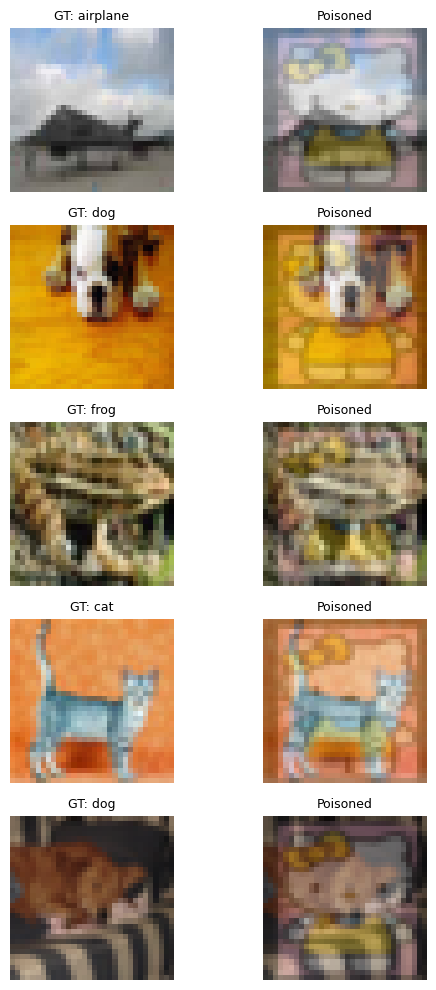

In [2]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# ---------------- CIFAR-10 测试集 ----------------
transform = transforms.ToTensor()
test_ds = datasets.CIFAR10(root='./data', train=False, transform=transform, download=True)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)

# ---------------- 评估函数 ----------------
def evaluate_clean_accuracy(model, loader):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(next(model.parameters()).device)
            labels = labels.to(next(model.parameters()).device)
            outputs = model(imgs)
            _, preds = outputs.max(1)
            total += labels.size(0)
            correct += preds.eq(labels).sum().item()
    print(f"Clean Accuracy: {correct / total * 100:.2f}%")

def evaluate_asr(model, dataset, target_class, trigger, alpha=0.3):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for img, _ in dataset:
            poisoned = (1 - alpha) * img + alpha * trigger
            poisoned = poisoned.unsqueeze(0).to(next(model.parameters()).device)
            out = model(poisoned)
            pred = out.argmax(dim=1).item()
            total += 1
            if pred == target_class:
                correct += 1
    print(f"Attack Success Rate (ASR): {correct / total * 100:.2f}%")

# ---------------- 可视化（原图 vs 加触发器） ----------------
CIFAR10_CLASSES = (
    "airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"
)

def _tensor_to_np(img_tensor):
    return np.transpose(img_tensor.cpu().numpy(), (1,2,0))

def visualize_trigger_effect(dataset, trigger_tensor, alpha=0.3, n_samples=6):
    trigger_cpu = trigger_tensor.cpu()
    idxs = list(range(len(dataset)))
    random.shuffle(idxs)
    picked = idxs[:n_samples]

    plt.figure(figsize=(6, n_samples*2))
    for i, idx in enumerate(picked):
        img, label = dataset[idx]
        poisoned = (1 - alpha) * img + alpha * trigger_cpu

        # 原图
        ax1 = plt.subplot(n_samples, 2, 2*i + 1)
        ax1.imshow(_tensor_to_np(img))
        ax1.axis('off')
        ax1.set_title(f"GT: {CIFAR10_CLASSES[label]}", fontsize=9)

        # 加 trigger 后
        ax2 = plt.subplot(n_samples, 2, 2*i + 2)
        ax2.imshow(_tensor_to_np(poisoned))
        ax2.axis('off')
        ax2.set_title("Poisoned", fontsize=9)
    plt.tight_layout()
    plt.show()

# 加载 SimpleCNN 模型并执行评估（注意：假设 load_model、trigger、alpha 在其他地方已定义）
model = load_model("cifar10_blend_cnn4.pth")  
evaluate_clean_accuracy(model, test_loader)
evaluate_asr(model, test_ds, target_class=0, trigger=trigger, alpha=alpha)
# --- 可视化效果 ---
visualize_trigger_effect(test_ds, trigger, alpha=alpha, n_samples=5)


In [3]:
import torch
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms

# ✅ 1. 定义检测函数（使用真实中毒 index 判定是否为 poison）
def evaluate_detection(model, loader, threshold, poison_index_set):
    TP = FP = P = N = 0
    model.eval()
    current_idx = 0

    with torch.no_grad():
        for imgs, _ in loader:
            batch_size = imgs.size(0)
            imgs = imgs.to(next(model.parameters()).device)
            outputs = model(imgs)
            probs = torch.softmax(outputs, dim=1)
            confs, _ = probs.max(dim=1)

            for i in range(batch_size):
                global_idx = current_idx + i
                is_true_poison = (global_idx in poison_index_set)
                is_pred_poison = (confs[i].item() >= threshold)

                if is_true_poison:
                    P += 1
                    if is_pred_poison:
                        TP += 1
                else:
                    N += 1
                    if is_pred_poison:
                        FP += 1

            current_idx += batch_size

    print(f"TPR: {TP}/{P} = {TP/P:.4f}" if P > 0 else "TPR: N/A")
    print(f"FPR: {FP}/{N} = {FP/N:.4f}" if N > 0 else "FPR: N/A")


# ✅ 2. 参数设定
poison_rate = 0.5
threshold = 0.95
batch_size = 128
alpha = 0.3
target_class = 0
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = load_model("cifar10_blend_cnn4.pth")

# ✅ 4. 加载原始测试集
transform = transforms.ToTensor()
test_ds = datasets.CIFAR10('./data', train=False, transform=transform, download=True)

# ✅ 7. 创建中毒测试集
poisoner_test = BlendPoisoner(
    dataset=test_ds,
    poison_rate=poison_rate,
    target_class=target_class,
    alpha=alpha,
    trigger=trigger
)
poisoned_test_ds = poisoner_test.generate_combined_dataset()
poisoned_test_loader = DataLoader(poisoned_test_ds, batch_size=batch_size, shuffle=False)


# ✅ 8. 获取真实 poison index
_, _, poison_idxs = poisoner_test.generate_poison_only()
poisoned_index_set = set(poison_idxs)


# ✅ 9. 调用检测函数评估
evaluate_detection(model, poisoned_test_loader, threshold, poisoned_index_set)


Files already downloaded and verified
[INFO] Combined dataset size: 15000 (Clean: 10000, Poison: 5000)
TPR: 4038/5000 = 0.8076
FPR: 8835/10000 = 0.8835


In [4]:
import torch
import numpy as np
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# 1️⃣ 加载 ResNet18 模型（来自第一段）
model = load_model("cifar10_blend_cnn4.pth")  # ✅ 改成 blend 模型
model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# 2️⃣ 准备测试数据集
transform = transforms.ToTensor()
test_ds = datasets.CIFAR10(root='./data', train=False, transform=transform, download=True)

# 获取真实中毒样本索引
_, _, poison_idxs = poisoner_test.generate_poison_only()
poisoned_index_set = set(poison_idxs)

# 4️⃣ 遍历 loader，筛选高置信度样本
high_conf_indices = []
high_conf_labels = []  # 1 = poison, 0 = clean
current_idx = 0

with torch.no_grad():
    for imgs, _ in poisoned_test_loader:
        batch_size = imgs.size(0)
        imgs = imgs.to(device)
        outputs = model(imgs)
        probs = torch.softmax(outputs, dim=1)
        confs, _ = torch.max(probs, dim=1)

        mask_conf = confs > 0.95  # 阈值
        indices = torch.arange(current_idx, current_idx + batch_size)[mask_conf.cpu()]
        high_conf_indices.extend(indices.tolist())

        # 标记 poison / clean
        for idx in indices:
            label = 1 if idx.item() in poisoned_index_set else 0
            high_conf_labels.append(label)

        current_idx += batch_size

print(f"[INFO] Found {len(high_conf_indices)} samples with confidence > 0.95")

# 5️⃣ 保存结果
np.save("high_confidence_idxs-cbc.npy", np.array(high_conf_indices))
np.save("high_confidence_labels-cbc.npy", np.array(high_conf_labels))


Files already downloaded and verified
[INFO] Found 12873 samples with confidence > 0.95


In [5]:
import torch
import numpy as np
from sklearn.metrics import balanced_accuracy_score

# ✅ 2. 加载 Blend 模型
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.load_state_dict(torch.load("cifar10_blend_cnn4.pth", map_location=device))
model.eval()

# ✅ 3. 定义自影响计算函数
def compute_self_influence_for_high_conf(model, test_dataset,
    high_conf_indices_path="high_confidence_idxs-cbc.npy",
    high_conf_labels_path="high_confidence_labels-cbc.npy",
    target_class=0):

    device = next(model.parameters()).device
    model.eval()

    high_conf_indices = np.load(high_conf_indices_path)
    high_conf_labels = np.load(high_conf_labels_path)

    print(f"[INFO] Loaded {len(high_conf_indices)} high-confidence samples.")
    high_conf_sifs = []

    for idx, is_poison in zip(high_conf_indices, high_conf_labels):
        img, true_label = test_dataset[idx]
        img = img.unsqueeze(0).to(device).requires_grad_(True)

        # poison 样本使用目标标签，干净样本使用原始标签
        label_tensor = torch.tensor([target_class if is_poison == 1 else true_label]).to(device)

        model.zero_grad()
        output = model(img)
        loss = torch.nn.functional.cross_entropy(output, label_tensor)
        grads = torch.autograd.grad(loss, model.parameters(), create_graph=False)

        grad_norm = sum(g.detach().norm().item()**2 for g in grads)
        high_conf_sifs.append(grad_norm)

    sif_array = np.array(high_conf_sifs)
    return sif_array, high_conf_labels, high_conf_indices

# ✅ 4. 运行自影响函数分析（需先运行第四段：高置信度样本筛选）
sif_values, sif_labels, high_conf_indices = compute_self_influence_for_high_conf(
    model,
    poisoned_test_ds,  # 来自第四段 (BlendPoisoner 生成的 poisoned_test_ds)
    high_conf_indices_path="high_confidence_idxs-cbc.npy",
    high_conf_labels_path="high_confidence_labels-cbc.npy",
    target_class=0
)

# ✅ 5. 分离中毒 / 干净样本的 SIF 值
sif_values = np.array(sif_values)
sif_labels = np.array(sif_labels)
sif_m = sif_values[sif_labels == 1]
sif_nm = sif_values[sif_labels == 0]

print(f"[INFO] 中毒样本数: {len(sif_m)}")
print(f"[INFO] 干净样本数: {len(sif_nm)}")

# ✅ 6. 搜索最优 SIF 区间
def find_best_threshold_interval(sif_m, sif_nm, num_steps=200):
    sif_m = np.array(sif_m)
    sif_nm = np.array(sif_nm)
    if len(sif_m) == 0 or len(sif_nm) == 0:
        return 0, 1  # fallback

    all_sif = np.concatenate([sif_m, sif_nm])
    all_labels = np.concatenate([np.ones(len(sif_m)), np.zeros(len(sif_nm))])
    thresholds = np.linspace(all_sif.min(), all_sif.max(), num_steps)

    best_acc = 0
    best_tau1, best_tau2 = 0, 0

    for i in range(len(thresholds)):
        tau1 = thresholds[i]
        for j in range(i + 1, len(thresholds)):
            tau2 = thresholds[j]
            y_pred = ((all_sif > tau1) & (all_sif < tau2)).astype(int)
            acc = balanced_accuracy_score(all_labels, y_pred)

            if acc > best_acc:
                best_acc = acc
                best_tau1, best_tau2 = tau1, tau2

    return best_tau1, best_tau2

# ✅ 7. 使用最优区间评估 TPR 和 FPR
def evaluate_by_interval(sif_m, sif_nm, tau1, tau2):
    tp = sum(tau1 < x < tau2 for x in sif_m)
    fp = sum(tau1 < x < tau2 for x in sif_nm)
    fn = len(sif_m) - tp
    tn = len(sif_nm) - fp

    tpr = tp / (tp + fn + 1e-10)
    fpr = fp / (fp + tn + 1e-10)

    print(f"[RESULT] 最佳区间: tau1 = {tau1:.6f}, tau2 = {tau2:.6f}")
    print(f"[RESULT] TPR: {tp}/{len(sif_m)} = {tpr*100:.2f}%")
    print(f"[RESULT] FPR: {fp}/{len(sif_nm)} = {fpr*100:.2f}%")
    return tpr, fpr, tp, fp, fn, tn

# ✅ 8. 主流程
tau1, tau2 = find_best_threshold_interval(sif_m, sif_nm)
tpr, fpr, tp, fp, fn, tn = evaluate_by_interval(sif_m, sif_nm, tau1, tau2)

accuracy = (tp + tn) / (tp + fp + fn + tn )
precision = tp / (tp + fp )
recall = tp / (tp + fn )

[INFO] Loaded 12873 high-confidence samples.
[INFO] 中毒样本数: 4021
[INFO] 干净样本数: 8852
[RESULT] 最佳区间: tau1 = 1983.097410, tau2 = 351008.241553
[RESULT] TPR: 3580/4021 = 89.03%
[RESULT] FPR: 1227/8852 = 13.86%


In [6]:
# ====== 第一部分：直接计算 TPR@不同FPR ======
from sklearn.metrics import roc_curve
import numpy as np

# 标签：1=poison, 0=clean
y_true = np.concatenate([np.ones(len(sif_m)), np.zeros(len(sif_nm))])
# SIF 分数
y_scores = np.concatenate([sif_m, sif_nm])

# 计算 ROC 曲线
fpr_vals, tpr_vals, thresholds = roc_curve(y_true, y_scores)

def tpr_at_fpr(target_fpr):
    """在给定FPR下插值找到TPR"""
    idx = np.argmin(np.abs(fpr_vals - target_fpr))
    return tpr_vals[idx], fpr_vals[idx]

targets = [0.1, 0.01, 0.001]
print("\n[TPR @ 不同 FPR]")
for target in targets:
    tpr_value, real_fpr = tpr_at_fpr(target)
    print(f"目标FPR={target:.3f} → 实际FPR={real_fpr*100:.4f}%, "
          f"TPR={tpr_value*100:.2f}%")

print(f"\n通过实验观察，阈值可以大概确定在 ({tau1:.6f}, {tau2:.6f})，"
      f"对应的FPR和TPR分别是 {fpr*100:.2f}% 和 {tpr*100:.2f}%")


[TPR @ 不同 FPR]
目标FPR=0.100 → 实际FPR=10.0090%, TPR=73.27%
目标FPR=0.010 → 实际FPR=0.9941%, TPR=8.93%
目标FPR=0.001 → 实际FPR=0.1017%, TPR=0.62%

通过实验观察，阈值可以大概确定在 (1983.097410, 351008.241553)，对应的FPR和TPR分别是 13.86% 和 89.03%


[INFO] 成功载入第二段 ROC 数据 (LOI-cifar10-Blend-cnn4)


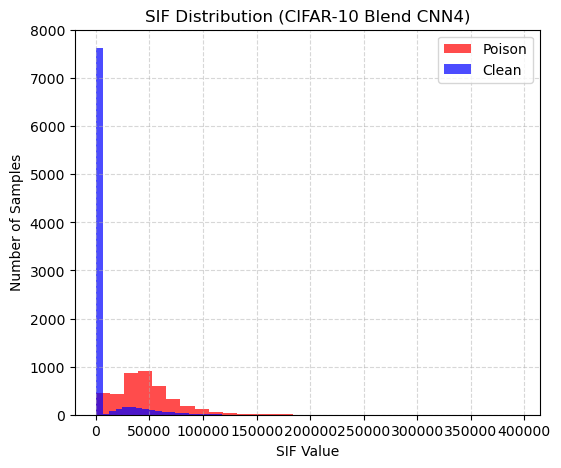

[SAVED] SIF 分布图已保存到：C:\Users\Lenovo\Desktop\实验数据\cifar10_blend_cnn4_SIF_Distribution.png


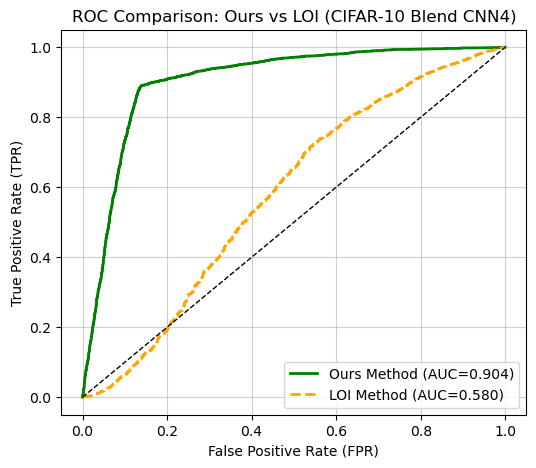

[SAVED] ROC 对比图已保存到：C:\Users\Lenovo\Desktop\实验数据\cifar10_blend_cnn4_ROC_Comparison.png

[METRICS]
Accuracy:  87.04%
Precision: 74.47%
Recall:    89.03%
AUC:       90.40%


In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import numpy as np
import os

# ===== 输出文件夹路径 =====
save_dir = r"C:\Users\Lenovo\Desktop\实验数据"
os.makedirs(save_dir, exist_ok=True)

# ===== 读取第二段 ROC 数据 =====
fpr2 = np.load("loi_cifar10_fullblend_cnn4-roc2_fpr.npy")
tpr2 = np.load("loi_cifar10_fullblend_cnn4-roc2_tpr.npy")
auc2 = np.load("loi_cifar10_fullblend_cnn4-roc2_auc.npy")[0]

print("[INFO] 成功载入第二段 ROC 数据 (LOI-cifar10-Blend-cnn4)")

# ===== 标签与分数 =====
y_true = np.concatenate([np.ones(len(sif_m)), np.zeros(len(sif_nm))])
y_scores = np.concatenate([sif_m, sif_nm])

# ===== ROC 曲线 =====
fpr_vals, tpr_vals, _ = roc_curve(y_true, y_scores)
roc_auc = auc(fpr_vals, tpr_vals)

# =============================
# 图1：SIF 分布直方图
# =============================
plt.figure(figsize=(6,5))
plt.hist(sif_m, bins=30, alpha=0.7, label='Poison', color='red')
plt.hist(sif_nm, bins=30, alpha=0.7, label='Clean', color='blue')
plt.xlabel('SIF Value')
plt.ylabel('Number of Samples')
plt.title('SIF Distribution (CIFAR-10 Blend CNN4)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# 保存图1
save_path1 = os.path.join(save_dir, "cifar10_blend_cnn4_SIF_Distribution.png")
plt.savefig(save_path1, dpi=300, bbox_inches='tight')
plt.show()
print(f"[SAVED] SIF 分布图已保存到：{save_path1}")

# =============================
# 图2：ROC 对比图
# =============================
plt.figure(figsize=(6,5))
plt.plot(fpr_vals, tpr_vals, lw=2, label=f"Ours Method (AUC={roc_auc:.3f})", color='green')
plt.plot(fpr2, tpr2, lw=2, linestyle='--', label=f"LOI Method (AUC={auc2:.3f})", color='orange')
plt.plot([0,1],[0,1],'k--', lw=1)
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Comparison: Ours vs LOI (CIFAR-10 Blend CNN4)")
plt.legend(loc="lower right")
plt.grid(alpha=0.6)

# 保存图2
save_path2 = os.path.join(save_dir, "cifar10_blend_cnn4_ROC_Comparison.png")
plt.savefig(save_path2, dpi=300, bbox_inches='tight')
plt.show()
print(f"[SAVED] ROC 对比图已保存到：{save_path2}")

# ===== 打印指标 =====
print("\n[METRICS]")
print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"AUC:       {roc_auc * 100:.2f}%")


In [9]:
print("\n================ Manual Single Threshold Baselines =================")

# 所有样本的 SIF 与标签
all_sif = np.concatenate([sif_m, sif_nm])
all_labels = np.concatenate([np.ones(len(sif_m)), np.zeros(len(sif_nm))])

# 你导师指定区间
tau1_manual = 10607
tau2_manual = 281859

# 人工选 5 个整数
taus = [10000, 50000, 150000, 200000, 250000]

for tau in taus:
    y_pred = (all_sif > tau).astype(int)

    tp = np.sum((y_pred == 1) & (all_labels == 1))
    fp = np.sum((y_pred == 1) & (all_labels == 0))
    fn = np.sum((y_pred == 0) & (all_labels == 1))
    tn = np.sum((y_pred == 0) & (all_labels == 0))

    tpr = tp / (tp + fn + 1e-10)
    fpr = fp / (fp + tn + 1e-10)

    print(f"τ = {tau:>8d} | TPR = {tpr*100:.2f}% | FPR = {fpr*100:.2f}%")


================ Manual Single Threshold Baselines =================
τ =    10000 | TPR = 88.83% | FPR = 13.83%
τ =    50000 | TPR = 37.18% | FPR = 4.78%
τ =   150000 | TPR = 0.65% | FPR = 0.10%
τ =   200000 | TPR = 0.17% | FPR = 0.00%
τ =   250000 | TPR = 0.07% | FPR = 0.00%


In [10]:
print("\n================ Manual Double Threshold Baselines =================")

intervals = [
    (10000, 50000),
    (10000, 150000),
    (50000, 200000),
    (50000, 250000),
    (150000, 250000),
]

for tau_low, tau_high in intervals:
    y_pred = ((all_sif > tau_low) & (all_sif < tau_high)).astype(int)

    tp = np.sum((y_pred == 1) & (all_labels == 1))
    fp = np.sum((y_pred == 1) & (all_labels == 0))
    fn = np.sum((y_pred == 0) & (all_labels == 1))
    tn = np.sum((y_pred == 0) & (all_labels == 0))

    tpr = tp / (tp + fn + 1e-10)
    fpr = fp / (fp + tn + 1e-10)

    print(f"[{tau_low:>6d}, {tau_high:<6d}] | "
          f"TPR = {tpr*100:.2f}% | FPR = {fpr*100:.2f}%")


================ Manual Double Threshold Baselines =================
[ 10000, 50000 ] | TPR = 51.65% | FPR = 9.05%
[ 10000, 150000] | TPR = 88.19% | FPR = 13.73%
[ 50000, 200000] | TPR = 37.01% | FPR = 4.78%
[ 50000, 250000] | TPR = 37.11% | FPR = 4.78%
[150000, 250000] | TPR = 0.57% | FPR = 0.10%
